In [ ]:
!pip install -q datasets

In [ ]:
import pandas as pd, html, re
from datasets import load_dataset
from google.colab import drive

drive.mount('/content/drive')
D = "/content/drive/MyDrive/My_Projects/EmotionLens/"
names = {0: "negative", 1: "neutral", 2: "positive"}

def fix_text(t):
    t = re.sub(r"\\u([0-9a-fA-F]{4})", lambda m: chr(int(m.group(1), 16)), t)
    return html.unescape(t)

preds = pd.read_csv(D + "test_predictions.csv")

# 100 tweets where the ready-made model was wrong
wrong = preds[preds["label"] != preds["rob_pred"]].sample(100, random_state=7)
a = pd.DataFrame({
    "source": "mistake",
    "text": wrong["text_fixed"].values,
    "dataset_label": wrong["label"].map(names).values,
    "rob_pred": wrong["rob_pred"].map(names).values,
    "ft_pred": wrong["ft_pred"].map(names).values})

# 50 ironic (sarcastic) tweets
irony = load_dataset("cardiffnlp/tweet_eval", "irony")["test"].to_pandas()
irony = irony[irony["label"] == 1].sample(50, random_state=7)
b = pd.DataFrame({
    "source": "irony",
    "text": irony["text"].apply(fix_text).values,
    "dataset_label": "", "rob_pred": "", "ft_pred": ""})

allrows = pd.concat([a, b]).sample(frac=1, random_state=1).reset_index(drop=True)
allrows.insert(0, "id", range(1, len(allrows) + 1))

sheet = allrows[["id", "text"]].copy()
for c in ["my_label", "sarcasm_yes_no", "error_type", "notes"]:
    sheet[c] = ""
key = allrows[["id", "source", "dataset_label", "rob_pred", "ft_pred"]]

sheet.to_csv(D + "hard_set_labeling_sheet.csv", index=False, encoding="utf-8-sig")
key.to_csv(D + "hard_set_answer_key.csv", index=False, encoding="utf-8-sig")
print(len(sheet), "tweets saved")

Mounted at /content/drive


README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

irony/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  183kB            

irony/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

irony/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 54.0kB            

...

irony/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2862 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/784 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/955 [00:00<?, ? examples/s]

150 tweets saved


In [ ]:
import pandas as pd
D = "/content/drive/MyDrive/My_Projects/EmotionLens/"
df = pd.read_csv(D + "hard_set_labeled.csv").fillna("")
print(df["my_label"].value_counts())
print(df["sarcasm_yes_no"].value_counts())
bad = df[~df["my_label"].isin(["negative", "neutral", "positive"]) |
         ~df["sarcasm_yes_no"].isin(["yes", "no"])]
print(len(bad), "rows to fix")
print(bad[["id", "my_label", "sarcasm_yes_no"]])

my_label
negative    97
neutral     33
positive    20
Name: count, dtype: int64
sarcasm_yes_no
no     97
yes    53
Name: count, dtype: int64
0 rows to fix
Empty DataFrame
Columns: [id, my_label, sarcasm_yes_no]
Index: []


In [ ]:
import pandas as pd, numpy as np, torch
from transformers import pipeline
from sklearn.metrics import f1_score

D = "/content/drive/MyDrive/My_Projects/EmotionLens/"
df = pd.read_csv(D + "hard_set_labeled.csv").fillna("")
key = pd.read_csv(D + "hard_set_answer_key.csv").fillna("")
df = df.merge(key, on="id")

dev = 0 if torch.cuda.is_available() else -1
fix = {"label_0": "negative", "label_1": "neutral", "label_2": "positive"}

def predict(model, texts):
    clf = pipeline("sentiment-analysis", model=model, device=dev,
                   batch_size=32, truncation=True, max_length=128)
    out = clf(texts)
    labels = [fix.get(o["label"].lower(), o["label"].lower()) for o in out]
    return labels, [o["score"] for o in out]

texts = df["text"].tolist()
df["rob"], df["rob_conf"] = predict("cardiffnlp/twitter-roberta-base-sentiment-latest", texts)
df["ft"], df["ft_conf"] = predict(D + "distilroberta_tweeteval", texts)

df.to_csv(D + "hard_set_with_predictions.csv", index=False, encoding="utf-8-sig")
print("done", len(df))

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

...

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

done 150


In [ ]:
def summary(sub, label):
    return {"group": label, "n": len(sub),
            "ready-made agrees with me": round((sub["rob"] == sub["my_label"]).mean(), 3),
            "my fine-tuned agrees with me": round((sub["ft"] == sub["my_label"]).mean(), 3)}

rows = [summary(df, "all 150")]
for s in ["no", "yes"]:
    rows.append(summary(df[df["sarcasm_yes_no"] == s], f"sarcasm = {s}"))
for s in ["mistake", "irony"]:
    rows.append(summary(df[df["source"] == s], f"source = {s}"))
print(pd.DataFrame(rows).to_string(index=False))

print("\nMacro-F1 vs my labels (all 150):")
print("  ready-made:", round(f1_score(df["my_label"], df["rob"], average="macro"), 3))
print("  fine-tuned:", round(f1_score(df["my_label"], df["ft"], average="macro"), 3))

m = df[df["source"] == "mistake"]
a = (m["my_label"] == m["dataset_label"]).sum()
b = (m["my_label"] == m["rob_pred"]).sum()
print(f"\nOf the 100 'mistake' tweets, my label agrees with:")
print(f"  the dataset label: {a}   the ready-made model: {b}   neither: {len(m) - a - b}")

print("\nAverage model confidence:")
print(df.groupby("sarcasm_yes_no")[["rob_conf", "ft_conf"]].mean().round(3))
unsure = df["notes"].str.contains("unsure", case=False)
print(df.groupby(unsure)[["rob_conf", "ft_conf"]].mean().round(3))

           group   n  ready-made agrees with me  my fine-tuned agrees with me
         all 150 150                      0.527                         0.460
    sarcasm = no  97                      0.598                         0.567
   sarcasm = yes  53                      0.396                         0.264
source = mistake 100                      0.560                         0.550
  source = irony  50                      0.460                         0.280

Macro-F1 vs my labels (all 150):
  ready-made: 0.47
  fine-tuned: 0.43

Of the 100 'mistake' tweets, my label agrees with:
  the dataset label: 30   the ready-made model: 57   neither: 13

Average model confidence:
                rob_conf  ft_conf
sarcasm_yes_no                   
no                 0.675    0.699
yes                0.698    0.707
       rob_conf  ft_conf
notes                   
False     0.684    0.702
True      0.667    0.702


In [ ]:
err = df[df["rob"] != df["my_label"]][["id", "text", "my_label", "rob", "ft", "sarcasm_yes_no"]].copy()
err["error_type"] = ""
err.to_csv(D + "error_review.csv", index=False, encoding="utf-8-sig")
print(len(err), "rows")

71 rows


In [3]:
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
D = "/content/drive/MyDrive/My_Projects/EmotionLens/"

e = pd.read_csv(D + "error_review_done.csv").fillna("")
print(len(e), "rows")
print(e["error_type"].value_counts())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
71 rows
error_type
sarcasm            31
context            19
news_vs_feeling    13
slang               5
other               1
label_doubt         1
mixed               1
Name: count, dtype: int64


In [4]:
print(e[e["error_type"] == ""]["id"].tolist())

[]


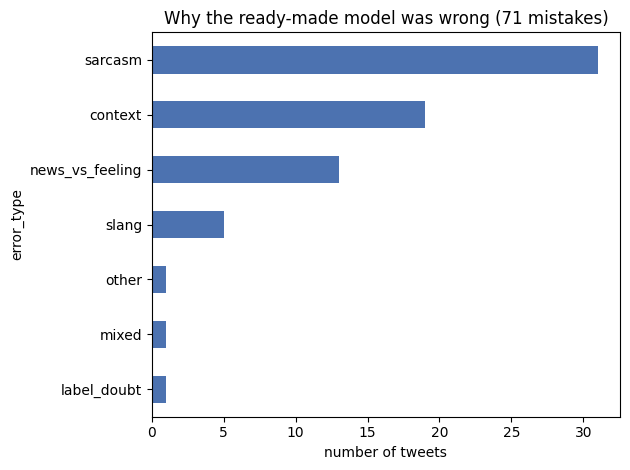

In [5]:
import matplotlib.pyplot as plt

counts = e[e["error_type"] != ""]["error_type"].value_counts().sort_values()
counts.plot(kind="barh", color="#4C72B0")
plt.title("Why the ready-made model was wrong (71 mistakes)")
plt.xlabel("number of tweets")
plt.tight_layout()
plt.savefig(D + "error_types.png", dpi=150)
plt.show()